![Tracing Agents with Langfuse](assets/banner-adv-03.svg)

Langfuse is an open source LLM engineering platform: tracing, prompt management, evaluations and datasets. Its Python SDK is built **on top of OpenTelemetry**, so everything from notebook 02 still applies. The SDK adds LLM-specific structure: typed observations, users, sessions, scores and automatic cost.

We will instrument the weather agent step by step and check the result in the UI at **http://localhost:3000** after each step.

## The Langfuse data model

| Concept | What it is | OpenTelemetry equivalent |
|---|---|---|
| **Trace** | One request or agent run | A trace |
| **Observation** | One step inside a trace, typed | A span |
| **Session** | Traces from one conversation, grouped by `session_id` | No direct equivalent |
| **User** | Traces from one end user, grouped by `user_id` | `user.id` attribute |
| **Score** | A judgement attached to a trace or observation: numeric, boolean, categorical | No direct equivalent |
| **Tags, metadata, version, environment** | Filterable context on every observation | Attributes and resource |

**Observation types** decide how the UI renders a step and what fields it expects:

| Type | Use for | Extra fields |
|---|---|---|
| `generation` | An LLM call | model, parameters, token usage, cost, prompt link |
| `embedding` | An embedding call | model, token usage, cost |
| `agent` | A step where an LLM decides what to do next | |
| `tool` | A single action: function or API call | |
| `retriever` | Read-only lookup from a vector store or database | |
| `chain` | Glue that passes data between steps | |
| `guardrail` | A safety or policy check | |
| `evaluator` | A step that judges another step's output | |
| `span` | Anything else that takes time | |
| `event` | A point in time with no duration | |

## 0. Connect

The SDK reads `LANGFUSE_PUBLIC_KEY`, `LANGFUSE_SECRET_KEY` and `LANGFUSE_BASE_URL` from the environment (loaded from the repo `.env` by `lab`).

In [1]:
import lab  # loads ../.env before Langfuse reads the environment
from langfuse import get_client

langfuse = get_client()
print("authenticated:", langfuse.auth_check())

authenticated: True


## 1. One line of instrumentation: the OpenAI drop-in

Swap `from openai import OpenAI` for `from langfuse.openai import OpenAI`. Every call now becomes a `generation` with the prompt, completion, model, parameters, latency, token usage and cost captured automatically.

In [2]:
from langfuse.openai import OpenAI

client = OpenAI()
MODEL = "gpt-4o-mini"

response = client.chat.completions.create(
    name="hello-generation",
    model=MODEL,
    messages=[{"role": "user", "content": "In one sentence, what is a trace in software observability?"}],
    max_tokens=60,
)
print(response.choices[0].message.content)
langfuse.flush()

A trace in software observability is a record of the sequence of requests and interactions within a distributed system, capturing the flow of operations across services to help diagnose performance issues and understand system behavior.


Open **Tracing** in the UI. You will find a trace named `hello-generation` with a single generation inside. Click it to see the full prompt, completion, token counts and computed cost.

## 2. Build the trace tree with `@observe`

The `@observe` decorator wraps a function in an observation. It records arguments as input, the return value as output, timing, and exceptions. Nested decorated functions become children, through the same context propagation we saw in notebook 02. `as_type` picks the observation type.

In [3]:
from langfuse import observe


@observe(as_type="retriever")
def search_docs(question: str) -> list[str]:
    return lab.search_docs_impl(question)


@observe(as_type="tool")
def get_weather(city: str) -> dict:
    for attempt in range(3):
        try:
            return lab.get_weather_impl(city)
        except TimeoutError:
            langfuse.update_current_span(metadata={"retries": attempt + 1})
    raise TimeoutError(f"weather unavailable for {city} after 3 attempts")


@observe(as_type="agent")
def answer_question(question: str, city: str) -> str:
    docs = search_docs(question)
    weather = get_weather(city)
    response = client.chat.completions.create(
        name="answer",
        model=MODEL,
        messages=lab.build_messages(question, docs, weather),
        max_tokens=80,
    )
    return response.choices[0].message.content


print(answer_question("What's the weather in Paris, and should I carry an umbrella?", "Paris"))
langfuse.flush()

The weather in Paris is 14°C with a 70% chance of rain, so you should carry an umbrella.


Langfuse also exposes everything over a public API. We read the trace back and draw it here, next to its link in the UI.

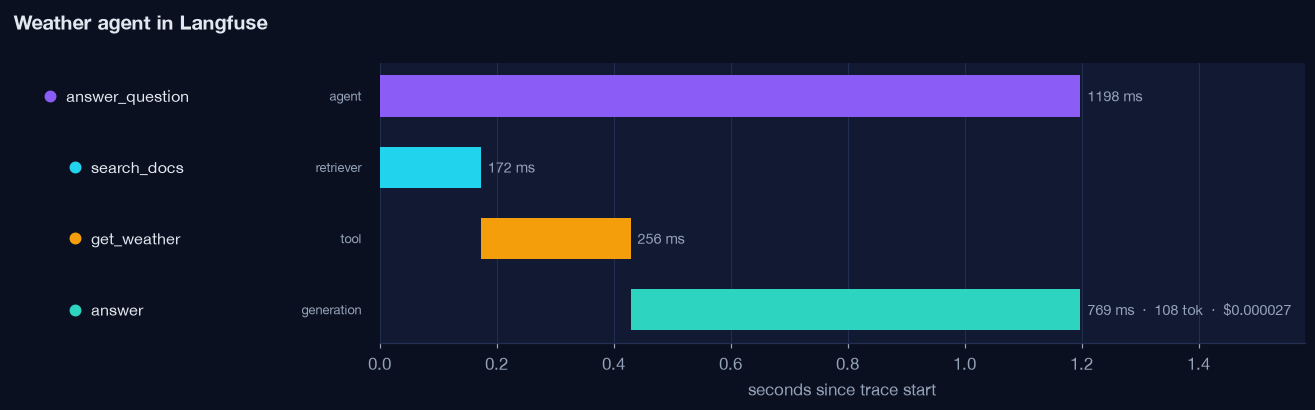

http://localhost:3000/project/weather-agent/traces/e768866a05b527eefbb91b8f1447abc1


In [4]:
import time

time.sleep(3)
obs = lab.langfuse_observations(limit=20, name="answer_question")
last = obs.sort_values("startTime")["traceId"].iloc[-1]
lab.show_trace(last, "Weather agent in Langfuse");
print(langfuse.get_trace_url(trace_id=last))

## 3. Users, sessions, tags and versions

A single trace answers "what happened in this request". Real questions are broader:

- *What did this customer experience across the whole conversation?* needs a **session**.
- *Which users cost us the most?* needs a **user id**.
- *Did prompt v2 make answers worse?* needs a **version** or **tag**.

`propagate_attributes` sets these once and copies them onto every observation created inside the block.

In [5]:
import uuid

from langfuse import propagate_attributes


def chat_session(user_id: str, turns: list[tuple[str, str]], prompt_version: str = "v1"):
    session_id = f"chat-{uuid.uuid4().hex[:8]}"
    with propagate_attributes(
        user_id=user_id,
        session_id=session_id,
        tags=["weather-agent", "notebook-03"],
        version=prompt_version,
        metadata={"channel": "web"},
    ):
        for question, city in turns:
            try:
                answer = answer_question(question, city)
            except TimeoutError as exc:
                answer = f"(failed: {exc})"
            print(f"[{user_id}] {question}\n   -> {answer}\n")
    return session_id


session_a = chat_session(
    "ana@example.com",
    [
        ("Should I carry an umbrella in London today?", "London"),
        ("And do I need a jacket there?", "London"),
        ("What about Dubai tomorrow, umbrella or not?", "Dubai"),
    ],
)
session_b = chat_session("raj@example.com", [("Umbrella needed in Tokyo?", "Tokyo")])
langfuse.flush()

[ana@example.com] Should I carry an umbrella in London today?
   -> Yes, you should carry an umbrella in London today since the chance of rain is 85%.



[ana@example.com] And do I need a jacket there?
   -> Yes, you need a jacket since the temperature in London is 11 degrees Celsius, which is below 16 degrees.



[ana@example.com] What about Dubai tomorrow, umbrella or not?
   -> No umbrella is needed in Dubai tomorrow, as the chance of rain is 0%.



[raj@example.com] Umbrella needed in Tokyo?
   -> No, an umbrella is not needed in Tokyo since the chance of rain is only 20%.



In the UI:
- **Sessions** shows `chat-...` sessions; Ana's has three turns replayed as a conversation.
- **Users** lists both users with trace counts, token totals and cost.
- In **Tracing**, filter by tag `notebook-03` or by version `v1`.

## 4. Failures are first-class

When a decorated function raises, the observation is marked `ERROR` with the exception message, and the error bubbles up the tree. We force the weather API to fail every time to see it.

In [6]:
def weather_outage(city: str, flaky: bool = True) -> dict:
    time.sleep(0.4)
    raise TimeoutError(f"weather API timed out for {city}")


original = lab.get_weather_impl
lab.get_weather_impl = weather_outage
try:
    with propagate_attributes(user_id="ana@example.com", tags=["notebook-03", "incident"]):
        answer_question("Umbrella in Paris?", "Paris")
except TimeoutError as exc:
    print("request failed:", exc)
finally:
    lab.get_weather_impl = original
langfuse.flush()

request failed: weather unavailable for Paris after 3 attempts


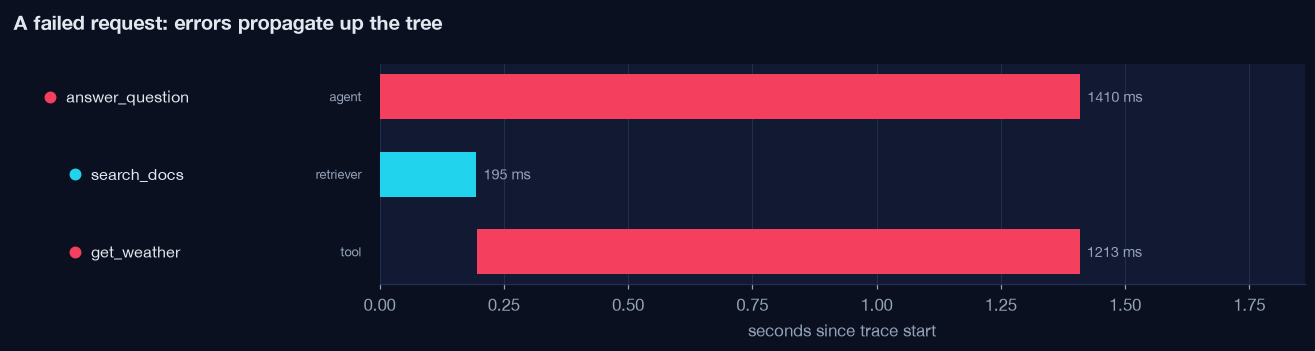

In [7]:
time.sleep(3)
failed = lab.langfuse_observations(limit=20, level="ERROR")
failed_trace = failed.sort_values("startTime")["traceId"].iloc[-1]
lab.show_trace(failed_trace, "A failed request: errors propagate up the tree");

Red bars are observations at level `ERROR`. In the UI, filter **Level = ERROR** to list every failing step across all traces.

## 5. Guardrails and evaluators

Two more observation types make the trace tell the whole story:

- a **guardrail** that checks the user input before the agent runs, and
- an **evaluator** that grades the answer after it is produced, using a second LLM call (LLM-as-a-judge).

The judge's verdict is stored as a **score** on the trace so it can be charted and filtered later.

In [8]:
import json
import re


@observe(as_type="guardrail")
def pii_guardrail(text: str) -> dict:
    found = re.findall(r"[\w.+-]+@[\w-]+\.[\w.]+|\b\d{3}[- ]?\d{3}[- ]?\d{4}\b", text)
    return {"passed": not found, "redacted": re.sub(r"[\w.+-]+@[\w-]+\.[\w.]+", "[email]", text)}


@observe(as_type="evaluator")
def judge_answer(question: str, answer: str) -> dict:
    verdict = client.chat.completions.create(
        name="judge",
        model=MODEL,
        response_format={"type": "json_object"},
        messages=[
            {
                "role": "system",
                "content": "Grade the assistant answer. Return JSON with helpfulness (0 to 1) and a short reason.",
            },
            {"role": "user", "content": f"Question: {question}\nAnswer: {answer}"},
        ],
        max_tokens=80,
    )
    return json.loads(verdict.choices[0].message.content)


@observe(as_type="chain", name="guarded-agent")
def guarded_agent(question: str, city: str) -> str:
    check = pii_guardrail(question)
    answer = answer_question(check["redacted"], city)
    grade = judge_answer(check["redacted"], answer)
    langfuse.score_current_trace(name="helpfulness", value=float(grade["helpfulness"]), comment=grade["reason"])
    langfuse.score_current_trace(name="pii_detected", value=not check["passed"], data_type="BOOLEAN")
    return answer


with propagate_attributes(user_id="raj@example.com", tags=["notebook-03"]):
    print(guarded_agent("I'm raj@example.com, do I need an umbrella in London?", "London"))
langfuse.flush()

Yes, you should carry an umbrella in London since the chance of rain is 85%.


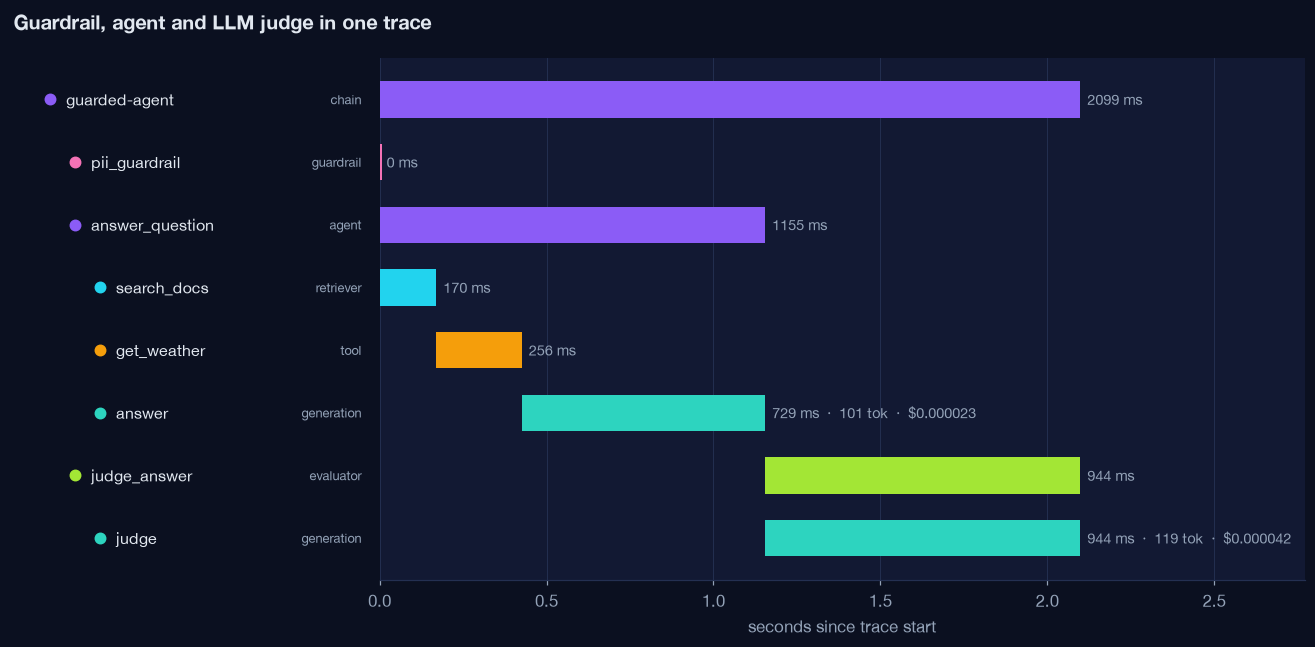

In [9]:
time.sleep(3)
guarded = lab.langfuse_observations(limit=5, name="guarded-agent")
gtrace = guarded.sort_values("startTime")["traceId"].iloc[-1]
lab.show_trace(gtrace, "Guardrail, agent and LLM judge in one trace");

## 6. Human feedback

Scores do not have to come from code running inside the trace. A thumbs up or down from your frontend arrives later, so you attach it by `trace_id`. This is how user feedback becomes a metric you can track against prompt versions.

In [10]:
langfuse.create_score(trace_id=gtrace, name="user_feedback", value=1, data_type="NUMERIC", comment="thumbs up")
langfuse.flush()
print("feedback attached to", langfuse.get_trace_url(trace_id=gtrace))

feedback attached to http://localhost:3000/project/weather-agent/traces/2c58d34cd6868fef9caa2e4ea6274aee


## 7. Keeping sensitive data out

By default the SDK captures inputs and outputs. Two controls matter in production:

```python
# 1. Turn off capture for one function
@observe(capture_input=False, capture_output=False)
def handle_payment(card_number): ...

# 2. Mask everything before it leaves the process
def mask(data, **kwargs):
    return re.sub(r"[\w.+-]+@[\w-]+\.[\w.]+", "[email]", str(data))

langfuse = Langfuse(mask=mask)
```

Self-hosting, as we do here, keeps all of it on infrastructure you control.

## 8. What we built, in numbers

Everything above is now queryable. Because `user_id` was propagated to every observation, one API call per user pulls their full activity into pandas.

In [11]:
import pandas as pd

ours = pd.concat(lab.langfuse_observations(userId=u) for u in ["ana@example.com", "raj@example.com"])
summary = (
    ours.groupby("type")
    .agg(count=("id", "count"), p50_latency=("latency", "median"), total_cost=("totalCost", "sum"))
    .sort_values("count", ascending=False)
)
summary.style.format({"p50_latency": "{:.2f}s", "total_cost": "${:.6f}"})

,count,p50_latency,total_cost
type,,,
generation,32,0.81s,$0.000824
agent,30,1.44s,$0.000000
retriever,30,0.17s,$0.000000
tool,30,0.93s,$0.000000
span,6,0.52s,$0.000000
chain,5,3.18s,$0.000000
evaluator,5,0.94s,$0.000000
guardrail,5,0.00s,$0.000000


## Tour of the UI

| Where | What to look at |
|---|---|
| **Tracing** | Trace list with latency, cost and tokens. Open any trace for the tree, timeline and input/output of each step |
| **Sessions** | Ana's three turns as one conversation |
| **Users** | Per-user trace count, tokens and cost |
| **Scores** | `helpfulness`, `pii_detected`, `user_feedback` |
| **Dashboards** | Latency percentiles, cost by model, traces over time |
| **Prompts** | Version prompts and link them to generations (next session) |

Next: [04 LangSmith](04_langsmith_in_depth.ipynb) shows the same agent in LangChain's platform, and [05 Analytics](05_analytics.ipynb) turns these traces into latency and cost answers.